# Stage 1 search analysis: baselines, validation and statistics

Reads the output of `genome_search.ipynb` and the input pool, and answers three questions:

1. **Baselines.** How do fixed input choices score on the same fitness? First 8 PCA, strongest 8, PLS 8 and mutual-information top 8, plus greedy forward selection with the twin.
2. **Validation.** Each run's best genome was the best of 1,000 on the inner frames, so its fitness is biased upward. Here every run's top genome (rank 1 by fitness, never picked by val) and every baseline is scored once on FF++ val with the twin, as video AUC with a bootstrap interval.
3. **Statistics.** Kruskal-Wallis across the main methods, then Mann-Whitney of each against random search with Holm correction, and the A12 effect size, on both fitness and val. DE and GWO are descriptive: A12 only.

It also saves the top 3 genomes of every run for the final-circuit notebook, and the two figures for the paper.

**The twin on val.** Trained the way `pool_prep` scores its bottleneck table: C picked from {0.001, 0.01, 0.1, 1} by frame AUC on the inner frames (trained on search-train), then refit on all FF++ train frames and scored on val. Twin features follow the circuit's gates (sin and cos, or cos only), the same rule as the search. The val numbers here are twin numbers; the real-circuit numbers come in the final-circuit notebook.

**Baselines and gates.** For the twin, the nine gate pairs reduce to two feature sets: [sin x, cos x] and cos x alone (RX or H+RZ encoding with an RY rotation). Each baseline input is scored with both and keeps the one with the higher fitness, so baselines get the same gate choice the search had. Greedy is run once per feature set.

## 1. Settings

In [1]:
backbones = ["l14", "b16", "effb4"]
main_methods = ["random", "GA", "PSO", "memetic GA"]   # tested against random search
descriptive_methods = ["DE", "GWO"]                      # A12 only
twin_c = 0.01                 # the search fitness, as in genome_search
c_grid = [0.001, 0.01, 0.1, 1.0]   # C picked on the inner split before val, as in pool_prep
fit_per_class = 1000
top_k = 3                     # genomes per run saved for the final circuits
n_boot = 1000
n_jobs = 0                    # 0 = one job per CPU core
machine_name = "kaggle"
seed = 0
out_dir = "/kaggle/working/search_analysis"

twin_sets = {"sin, cos": ("RY", "Rot"), "cos": ("RX", "RY")}   # one gate pair standing for each twin feature set

## 2. Imports

In [2]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
import glob
import json
import time
import platform
import multiprocessing as mp
import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib.pyplot as plt
from scipy.stats import kruskal, mannwhitneyu
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score

os.makedirs(out_dir, exist_ok=True)
if n_jobs == 0:
    n_jobs = os.cpu_count()
start_all = time.time()

## 3. Loading

In [3]:
def find_all(filename):
    return sorted(glob.glob("/kaggle/input/**/" + filename, recursive=True))


def find_one(filename, folder=None):
    hits = find_all(filename)
    if folder is not None:
        hits = [p for p in hits if os.path.basename(os.path.dirname(p)) == folder]
    assert len(hits) == 1, (filename, folder, hits)
    return hits[0]


search_log = pd.read_csv(find_one("search_log.csv", "genome_search"))
print("search log:", len(search_log), "evaluations,", search_log.groupby(["backbone", "method", "run"]).ngroups, "runs")
print(search_log.groupby(["backbone", "method"])["run"].nunique().unstack().to_string())

D = {}


def load_backbone(b):
    D.clear()
    pool_dir = os.path.dirname(find_one(f"{b}_ffpp_train_pool.npy"))
    train = np.load(f"{pool_dir}/{b}_ffpp_train_pool.npy").astype(np.float64)
    val = np.load(f"{pool_dir}/{b}_ffpp_val_pool.npy").astype(np.float64)
    rows = pd.read_csv(f"{pool_dir}/ffpp_train_rows.csv", dtype={"video_id": str})
    val_rows = pd.read_csv(f"{pool_dir}/ffpp_val_rows.csv", dtype={"video_id": str})
    is_inner = np.load(f"{pool_dir}/ffpp_train_is_inner.npy").astype(bool)
    columns = json.load(open(f"{pool_dir}/columns.json"))
    assert len(train) == len(rows) == len(is_inner) and len(val) == len(val_rows)
    assert train.shape[1] == val.shape[1] == len(columns)
    y = rows["label"].to_numpy()
    search = ~is_inner

    st_index = np.where(search)[0]
    st_rows = rows.iloc[st_index].copy()
    st_rows["row"] = st_index
    rng = np.random.default_rng(0)
    real_pick = st_rows[st_rows["label"] == 0].groupby("video_id").sample(n=2, random_state=0)["row"].to_numpy()
    fake_pick = st_rows[st_rows["label"] == 1].groupby(["method", "video_id"]).sample(n=1, random_state=0)["row"].to_numpy()
    fit_index = np.concatenate([rng.choice(real_pick, fit_per_class, replace=False),
                                rng.choice(fake_pick, fit_per_class, replace=False)])

    video = val_rows.groupby(["method", "video_id"]).ngroup().to_numpy()
    n_videos = video.max() + 1
    video_y = np.zeros(n_videos)
    video_y[video] = val_rows["label"].to_numpy()
    boot = np.random.default_rng(seed).integers(0, n_videos, (n_boot, n_videos))

    D.update(backbone=b, columns=columns, n_cols=len(columns), n_pca=sum(c.startswith("pca") for c in columns),
             train=train, val=val, y=y, search=search, is_inner=is_inner, fit_index=fit_index,
             inner_index=np.where(is_inner)[0], video=video, video_y=video_y,
             video_count=np.bincount(video, minlength=n_videos), boot=boot)
    print(f"{b}: train {train.shape}, val {val.shape}, {n_videos} val videos, "
          f"fit {len(fit_index)}, inner {is_inner.sum()}")

search log: 150000 evaluations, 150 runs
method    DE  GA  GWO  PSO  memetic GA  random
backbone                                      
b16        5  10    5   10          10      10
effb4      5  10    5   10          10      10
l14        5  10    5   10          10      10


## 4. The twin

`fitness` is the search fitness, unchanged: C = 0.01, trained on the 2,000 fitness frames, frame AUC on the inner frames. It takes any number of picks, which greedy needs.

`val_score` is the twin as a classifier: C picked on the inner split, refit on all train frames, video AUC on val with a 95% bootstrap interval.

In [4]:
def twin_features(x, g):
    if g["encoding"] != "RY" and g["rotation"] == "RY":
        return np.cos(x)
    return np.hstack([np.sin(x), np.cos(x)])


def twin_set(g):
    return "cos" if g["encoding"] != "RY" and g["rotation"] == "RY" else "sin, cos"


def twin_model(c):
    return make_pipeline(StandardScaler(), LogisticRegression(C=c, max_iter=5000))


def fitness(g):
    fi, ii, y = D["fit_index"], D["inner_index"], D["y"]
    x = D["train"][:, g["picks"]]
    model = twin_model(twin_c).fit(twin_features(x[fi], g), y[fi])
    return roc_auc_score(y[ii], model.predict_proba(twin_features(x[ii], g))[:, 1])


def video_auc(p):
    scores = np.bincount(D["video"], weights=p) / D["video_count"]
    auc = roc_auc_score(D["video_y"], scores)
    boot = [roc_auc_score(D["video_y"][i], scores[i]) for i in D["boot"]]
    return auc, np.percentile(boot, 2.5), np.percentile(boot, 97.5)


def val_score(g):
    y, search, inner = D["y"], D["search"], D["is_inner"]
    f_train = twin_features(D["train"][:, g["picks"]], g)
    inner_auc = {}
    for c in c_grid:
        model = twin_model(c).fit(f_train[search], y[search])
        inner_auc[c] = roc_auc_score(y[inner], model.predict_proba(f_train[inner])[:, 1])
    best_c = max(c_grid, key=lambda c: inner_auc[c])
    model = twin_model(best_c).fit(f_train, y)
    auc, low, high = video_auc(model.predict_proba(twin_features(D["val"][:, g["picks"]], g))[:, 1])
    return {"val_auc": auc, "val_low": low, "val_high": high, "val_c": best_c}


def key_of(g):
    return ".".join(D["columns"][p] for p in g["picks"]) + "|" + g["encoding"] + "|" + g["rotation"]


def with_set(picks, name):
    encoding, rotation = twin_sets[name]
    return {"picks": sorted(int(p) for p in picks), "encoding": encoding, "rotation": rotation}

## 5. Baselines

- **first 8 PCA**: the Phase 1 input.
- **strongest 8**: the 8 columns with the highest single-column AUC on search-train.
- **PLS 8**: the first 8 PLS components.
- **MI top 8**: the 8 columns with the highest mutual information with the label on search-train.
- **greedy**: forward selection with the search fitness. Starting from no columns, add the column that gives the highest fitness, eight times. Each pass costs 144 + 143 + ... + 137 = 1,124 fitness calls, and it runs once per twin feature set, so 2,248 calls per backbone, about twice a search run's budget.

Every baseline keeps the twin feature set with the higher fitness.

In [5]:
def greedy(name, workers):
    picks = []
    for step in range(8):
        candidates = [j for j in range(D["n_cols"]) if j not in picks]
        genomes = [with_set(picks + [j], name) for j in candidates]
        scores = workers.map(fitness, genomes)
        picks.append(candidates[int(np.argmax(scores))])
    return picks


def baselines(workers):
    y, search = D["y"], D["search"]
    train = D["train"]
    strength = []
    for j in range(D["n_cols"]):
        auc = roc_auc_score(y[search], train[search, j])
        strength.append(max(auc, 1 - auc))
    mi = mutual_info_classif(train[search], y[search], random_state=seed)
    masks = {
        "first 8 PCA": list(range(8)),
        "strongest 8": np.argsort(strength)[::-1][:8].tolist(),
        "PLS 8": list(range(D["n_pca"], D["n_pca"] + 8)),
        "MI top 8": np.argsort(mi)[::-1][:8].tolist(),
    }
    found = []
    for label, picks in masks.items():
        for name in twin_sets:
            g = with_set(picks, name)
            found.append({"baseline": label, "twin set": name, "genome": g, "fitness": fitness(g)})
    t0 = time.time()
    for name in twin_sets:
        g = with_set(greedy(name, workers), name)
        found.append({"baseline": "greedy", "twin set": name, "genome": g, "fitness": fitness(g)})
    print(D["backbone"], "greedy took %.0f s" % (time.time() - t0))
    found = pd.DataFrame(found)
    best = found.loc[found.groupby("baseline")["fitness"].idxmax()]
    return found, best

## 6. Run everything

For each backbone: the baselines, the top genomes of every run from the search log, and val for each run's top genome and each baseline. Genomes that appear twice (several runs found the same one) are scored once.

In [6]:
top_rows, val_rows_out, base_rows = [], [], []
for b in backbones:
    load_backbone(b)
    log = search_log[search_log["backbone"] == b]
    with mp.get_context("fork").Pool(n_jobs) as workers:
        found, best = baselines(workers)
        for _, r in found.iterrows():
            base_rows.append({"backbone": b, "baseline": r["baseline"], "twin set": r["twin set"],
                              "fitness": r["fitness"], "kept": r.name in best.index, "key": key_of(r["genome"]),
                              "genome": json.dumps(r["genome"])})

        top = log.sort_values("fitness", ascending=False).groupby(["method", "run"]).head(top_k).copy()
        top["rank"] = top.groupby(["method", "run"])["fitness"].rank(ascending=False, method="first").astype(int)
        top = top.sort_values(["method", "run", "rank"])
        for _, r in top.iterrows():
            g = json.loads(r["genome"])
            assert key_of(g) == r["key"], "the search log does not match this pool's columns"
            top_rows.append({"backbone": b, "method": r["method"], "run": r["run"], "rank": r["rank"],
                             "fitness": r["fitness"], "twin set": twin_set(g), "key": r["key"], "genome": r["genome"]})

        first = top[top["rank"] == 1]
        to_score = {}
        for g in [json.loads(s) for s in first["genome"]] + list(best["genome"]):
            to_score[key_of(g)] = g
        keys = list(to_score)
        t0 = time.time()
        scored = dict(zip(keys, workers.map(val_score, [to_score[k] for k in keys])))
        print(b, "val for %d genomes in %.0f s" % (len(keys), time.time() - t0))

    for _, r in first.iterrows():
        val_rows_out.append(dict({"backbone": b, "method": r["method"], "run": r["run"], "fitness": r["fitness"],
                                  "twin set": twin_set(json.loads(r["genome"])), "key": r["key"]}, **scored[r["key"]]))
    for _, r in best.iterrows():
        val_rows_out.append(dict({"backbone": b, "method": "baseline: " + r["baseline"], "run": 0,
                                  "fitness": r["fitness"], "twin set": r["twin set"], "key": key_of(r["genome"])},
                                 **scored[key_of(r["genome"])]))

top_genomes = pd.DataFrame(top_rows)
results = pd.DataFrame(val_rows_out)
base_table = pd.DataFrame(base_rows)
top_genomes.to_csv(f"{out_dir}/top_genomes.csv", index=False)
results.to_csv(f"{out_dir}/val_results.csv", index=False)
base_table.to_csv(f"{out_dir}/baselines.csv", index=False)
print("done in %.1f min" % ((time.time() - start_all) / 60))

l14: train (46076, 144), val (22396, 144), 700 val videos, fit 2000, inner 6912
l14 greedy took 10 s
l14 val for 52 genomes in 55 s
b16: train (46076, 144), val (22396, 144), 700 val videos, fit 2000, inner 6912
b16 greedy took 10 s
b16 val for 54 genomes in 54 s
effb4: train (46076, 144), val (22396, 144), 700 val videos, fit 2000, inner 6912
effb4 greedy took 11 s
effb4 val for 54 genomes in 64 s
done in 5.0 min


## 7. Baselines on fitness and val

Fitness of each baseline with both twin feature sets (the kept one is marked), then the kept ones on val.

In [7]:
print(base_table.drop(columns=["key", "genome"]).round(4).to_string(index=False))
print()
base_val = results[results["method"].str.startswith("baseline")].copy()
base_val["method"] = base_val["method"].str.replace("baseline: ", "")
print(base_val[["backbone", "method", "twin set", "fitness", "val_auc", "val_low", "val_high", "val_c", "key"]]
      .round(4).to_string(index=False))

backbone    baseline twin set  fitness  kept
     l14 first 8 PCA sin, cos   0.7343  True
     l14 first 8 PCA      cos   0.7297 False
     l14 strongest 8 sin, cos   0.8332  True
     l14 strongest 8      cos   0.8306 False
     l14       PLS 8 sin, cos   0.8658 False
     l14       PLS 8      cos   0.8678  True
     l14    MI top 8 sin, cos   0.8372  True
     l14    MI top 8      cos   0.8359 False
     l14      greedy sin, cos   0.8685 False
     l14      greedy      cos   0.8707  True
     b16 first 8 PCA sin, cos   0.6340  True
     b16 first 8 PCA      cos   0.6253 False
     b16 strongest 8 sin, cos   0.8234 False
     b16 strongest 8      cos   0.8255  True
     b16       PLS 8 sin, cos   0.8384 False
     b16       PLS 8      cos   0.8420  True
     b16    MI top 8 sin, cos   0.8264 False
     b16    MI top 8      cos   0.8295  True
     b16      greedy sin, cos   0.8431 False
     b16      greedy      cos   0.8466  True
   effb4 first 8 PCA sin, cos   0.5173 False
   effb4 f

## 8. Methods on fitness and val

One row per backbone and method: mean and standard deviation over runs of the best fitness and of the val AUC of each run's top genome, the range of val, and how many runs beat PLS 8 and greedy on val. The baselines' val numbers are the reference lines.

In [8]:
methods = main_methods + descriptive_methods
runs = results[results["method"].isin(methods)]
ref = base_val.set_index(["backbone", "method"])["val_auc"]

table = []
for b in backbones:
    for m in methods:
        r = runs[(runs["backbone"] == b) & (runs["method"] == m)]
        table.append({"backbone": b, "method": m, "runs": len(r),
                      "fitness mean": r["fitness"].mean(), "fitness sd": r["fitness"].std(),
                      "val mean": r["val_auc"].mean(), "val sd": r["val_auc"].std(),
                      "val min": r["val_auc"].min(), "val max": r["val_auc"].max(),
                      "runs above PLS 8": int((r["val_auc"] > ref[(b, "PLS 8")]).sum()),
                      "runs above greedy": int((r["val_auc"] > ref[(b, "greedy")]).sum()),
                      "cos-only runs": int((r["twin set"] == "cos").sum())})
table = pd.DataFrame(table)
table.to_csv(f"{out_dir}/method_table.csv", index=False)
print(table.round(4).to_string(index=False))

backbone     method  runs  fitness mean  fitness sd  val mean  val sd  val min  val max  runs above PLS 8  runs above greedy  cos-only runs
     l14     random    10        0.8379      0.0094    0.8470  0.0087   0.8334   0.8631                 0                  0              2
     l14         GA    10        0.8665      0.0036    0.8796  0.0072   0.8691   0.8893                 2                  0              9
     l14        PSO    10        0.8498      0.0100    0.8663  0.0149   0.8357   0.8883                 1                  0              4
     l14 memetic GA    10        0.8681      0.0017    0.8858  0.0053   0.8747   0.8928                 4                  0             10
     l14         DE     5        0.8323      0.0335    0.8481  0.0296   0.8120   0.8789                 0                  0              0
     l14        GWO     5        0.8450      0.0090    0.8633  0.0123   0.8449   0.8743                 0                  0              1
     b16     random 

## 9. Statistics

Per backbone and per measure (best fitness, val AUC of the top genome):
- Kruskal-Wallis across random search, GA, PSO and memetic GA.
- Mann-Whitney U (two-sided) of GA, PSO and memetic GA against random search, Holm-corrected over the three tests.
- A12 against random search: the chance that a run of the method scores higher than a run of random search (0.5 = no difference, 1 = always higher). DE and GWO get A12 only.

Run counts were fixed before the search and no runs were added afterwards.

In [9]:
def a12(x, y):
    x = np.asarray(x)[:, None]
    y = np.asarray(y)[None, :]
    return float(((x > y) + 0.5 * (x == y)).mean())


def holm(p):
    p = np.asarray(p)
    order = np.argsort(p)
    adjusted = np.empty(len(p))
    running = 0.0
    for i, j in enumerate(order):
        running = max(running, (len(p) - i) * p[j])
        adjusted[j] = min(1.0, running)
    return adjusted


stats = []
for b in backbones:
    for measure, col in [("fitness", "fitness"), ("val", "val_auc")]:
        groups = {m: runs[(runs["backbone"] == b) & (runs["method"] == m)][col].to_numpy() for m in methods}
        kw = kruskal(*[groups[m] for m in main_methods])
        tested = [m for m in main_methods if m != "random"]
        p_raw = [mannwhitneyu(groups[m], groups["random"], alternative="two-sided").pvalue for m in tested]
        p_holm = dict(zip(tested, holm(p_raw)))
        p_raw = dict(zip(tested, p_raw))
        for m in methods:
            if m == "random":
                continue
            stats.append({"backbone": b, "measure": measure, "method": m,
                          "mean diff vs random": groups[m].mean() - groups["random"].mean(),
                          "A12 vs random": a12(groups[m], groups["random"]),
                          "p": p_raw.get(m, np.nan), "p Holm": p_holm.get(m, np.nan),
                          "Kruskal-Wallis H": kw.statistic, "Kruskal-Wallis p": kw.pvalue})
stats = pd.DataFrame(stats)
stats.to_csv(f"{out_dir}/stats.csv", index=False)
print(stats.round(4).to_string(index=False))

backbone measure     method  mean diff vs random  A12 vs random      p  p Holm  Kruskal-Wallis H  Kruskal-Wallis p
     l14 fitness         GA               0.0286           0.98 0.0003  0.0007           29.8696            0.0000
     l14 fitness        PSO               0.0118           0.78 0.0376  0.0376           29.8696            0.0000
     l14 fitness memetic GA               0.0301           1.00 0.0002  0.0005           29.8696            0.0000
     l14 fitness         DE              -0.0056           0.54    NaN     NaN           29.8696            0.0000
     l14 fitness        GWO               0.0071           0.76    NaN     NaN           29.8696            0.0000
     l14     val         GA               0.0325           1.00 0.0002  0.0005           27.7630            0.0000
     l14     val        PSO               0.0193           0.89 0.0036  0.0036           27.7630            0.0000
     l14     val memetic GA               0.0388           1.00 0.0002  0.0005  

## 10. Figures

Fixed colors per method in both figures; random search is gray because it is the reference.

1. `anytime.png`: best fitness found so far against genomes evaluated, median over runs with the interquartile band. The dashed line is PLS 8 and the dotted line is greedy (which used 2,248 evaluations).
2. `val_auc.png`: val video AUC of each run's top genome, one dot per run, with the mean as a bar. The same two reference lines.

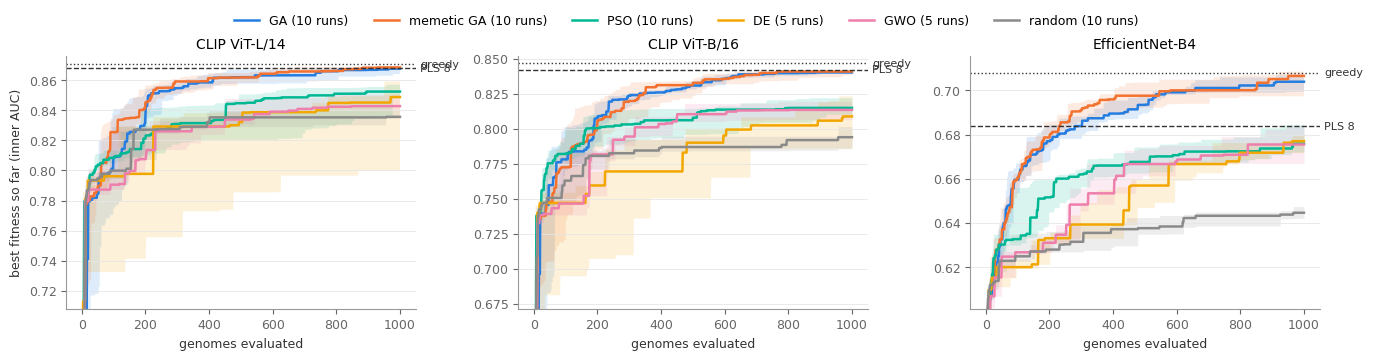

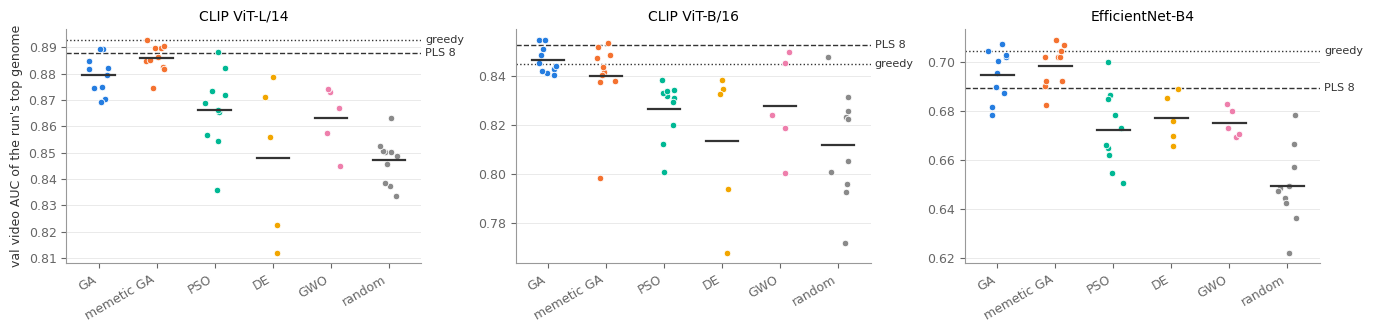

In [10]:
colors = {"GA": "#257de0", "memetic GA": "#f47230", "PSO": "#00b894", "DE": "#f2a600", "GWO": "#ee7fac",
          "random": "#8a8a8a"}
order = ["GA", "memetic GA", "PSO", "DE", "GWO", "random"]
titles = {"l14": "CLIP ViT-L/14", "b16": "CLIP ViT-B/16", "effb4": "EfficientNet-B4"}
base_fit = base_table[base_table["kept"]].set_index(["backbone", "baseline"])["fitness"]
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#999999", "axes.labelcolor": "#333333",
                     "xtick.color": "#666666", "ytick.color": "#666666"})


def reference_lines(ax, b, values):
    for label, style in [("PLS 8", "--"), ("greedy", ":")]:
        ax.axhline(values[(b, label)], color="#333333", linestyle=style, linewidth=1)
        ax.annotate(label, (1.0, values[(b, label)]), xycoords=("axes fraction", "data"), xytext=(3, 0),
                    textcoords="offset points", va="center", fontsize=8, color="#333333")


fig, axes = plt.subplots(1, len(backbones), figsize=(4.6 * len(backbones), 3.4))
for ax, b in zip(np.atleast_1d(axes), backbones):
    log = search_log[search_log["backbone"] == b]
    lows = []   # the plot starts where the slowest method's lower quartile is after 50 genomes
    for m in order:
        curves = []
        for _, g in log[log["method"] == m].groupby("run"):
            c = g.sort_values("eval")["fitness"].cummax().to_numpy()
            curves.append(np.pad(c, (0, 1000 - len(c)), mode="edge")[:1000])
        if len(curves) == 0:
            continue
        curves = np.array(curves)
        lows.append(np.percentile(curves[:, 49], 25))
        x = np.arange(1, curves.shape[1] + 1)
        ax.fill_between(x, np.percentile(curves, 25, axis=0), np.percentile(curves, 75, axis=0),
                        color=colors[m], alpha=0.15, linewidth=0)
        ax.plot(x, np.median(curves, axis=0), color=colors[m], linewidth=1.8, label=f"{m} ({len(curves)} runs)")
    reference_lines(ax, b, base_fit)
    refs = [base_fit[(b, "PLS 8")], base_fit[(b, "greedy")]]
    ax.set_ylim(min(lows + refs) - 0.01, max([log["fitness"].max()] + refs) + 0.005)
    ax.set_title(titles[b], fontsize=10)
    ax.set_xlabel("genomes evaluated")
    ax.grid(axis="y", color="#e6e6e6", linewidth=0.6)
np.atleast_1d(axes)[0].set_ylabel("best fitness so far (inner AUC)")
handles, labels = np.atleast_1d(axes)[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=len(labels), frameon=False, bbox_to_anchor=(0.5, 1.06))
plt.tight_layout()
plt.savefig(f"{out_dir}/anytime.png", dpi=200, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, len(backbones), figsize=(4.6 * len(backbones), 3.4))
rng = np.random.default_rng(seed)
for ax, b in zip(np.atleast_1d(axes), backbones):
    for i, m in enumerate(order):
        v = runs[(runs["backbone"] == b) & (runs["method"] == m)]["val_auc"].to_numpy()
        ax.scatter(i + rng.uniform(-0.18, 0.18, len(v)), v, s=22, color=colors[m], edgecolor="white", linewidth=0.6,
                   zorder=3)
        ax.plot([i - 0.28, i + 0.28], [v.mean(), v.mean()], color="#333333", linewidth=1.6, zorder=4)
    reference_lines(ax, b, ref)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(order, rotation=30, ha="right")
    ax.set_title(titles[b], fontsize=10)
    ax.grid(axis="y", color="#e6e6e6", linewidth=0.6)
np.atleast_1d(axes)[0].set_ylabel("val video AUC of the run's top genome")
plt.tight_layout()
plt.savefig(f"{out_dir}/val_auc.png", dpi=200, bbox_inches="tight")
plt.show()

## 11. Run log

In [11]:
info = {"finished": time.strftime("%Y-%m-%d %H:%M:%S"), "machine": machine_name, "backbones": backbones,
        "twin_c": twin_c, "c_grid": c_grid, "top_k": top_k, "n_boot": n_boot, "seed": seed, "n_jobs": n_jobs,
        "search_evaluations": int(len(search_log)), "total_minutes": round((time.time() - start_all) / 60, 1),
        "python": platform.python_version(), "numpy": np.__version__, "scipy": scipy.__version__,
        "sklearn": sklearn.__version__}
with open(f"{out_dir}/runs.jsonl", "a") as f:
    f.write(json.dumps(info) + "\n")
!ls -lh {out_dir}

total 464K
-rw-r--r-- 1 root root 196K Nov 26 15:41 anytime.png
-rw-r--r-- 1 root root 5.6K Nov 26 15:41 baselines.csv
-rw-r--r-- 1 root root 2.6K Nov 26 15:41 method_table.csv
-rw-r--r-- 1 root root  328 Nov 26 15:41 runs.jsonl
-rw-r--r-- 1 root root 3.3K Nov 26 15:41 stats.csv
-rw-r--r-- 1 root root  85K Nov 26 15:41 top_genomes.csv
-rw-r--r-- 1 root root 131K Nov 26 15:41 val_auc.png
-rw-r--r-- 1 root root  25K Nov 26 15:41 val_results.csv
